In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [6]:
class Node:

    def __init__(
            self,
            feature_index=None,
            threshold=None,
            left_child=None,
            right_child=None,
            prediction=None,
            is_leaf=False
    ):
        self.feature_index = feature_index
        self.threshold = threshold
        self.left_child = left_child
        self.right_child = right_child
        self.prediction = prediction
        self.is_leaf = is_leaf

In [7]:
class RandomForest:

    def __init__(
            self,
            n_estimators=100,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features=None
    ):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features

        self.trees = []


    # Gini Impurity

    def _gini(self, y):

        total = len(y)

        classes, counts = np.unique(y, return_counts=True)

        gini = 1

        for count in counts:
            p = count / total
            gini -= p ** 2

        return gini


    # Entropy

    def _entropy(self, y):

        total = len(y)

        classes, counts = np.unique(y, return_counts=True)

        entropy = 0

        for count in counts:

            p = count / total

            if p > 0:
                entropy -= p * np.log2(p)

        return entropy


    # Information Gain

    def _information_gain(self, y, left_y, right_y):

        parent_impurity = self._gini(y)

        n = len(y)
        n_left = len(left_y)
        n_right = len(right_y)

        split_impurity = (
                (n_left / n) * self._gini(left_y)
                + (n_right / n) * self._gini(right_y)
        )

        information_gain = parent_impurity - split_impurity

        return information_gain


    # Thresholds

    def _get_thresholds(self, feature_values):

        unique_values = np.unique(feature_values)
        unique_values = np.sort(unique_values)

        thresholds = (
                             unique_values[:-1] + unique_values[1:]
                     ) / 2

        return thresholds


    # Split Function

    def _split(self, X, y, feature_index, threshold):

        left_mask = X[:, feature_index] <= threshold
        right_mask = X[:, feature_index] > threshold

        X_left = X[left_mask]
        y_left = y[left_mask]

        X_right = X[right_mask]
        y_right = y[right_mask]

        return X_left, y_left, X_right, y_right


    # Finding Best Split

    def _find_best_split(self, X, y):

        best_gain = -np.inf
        best_feature = None
        best_threshold = None
        best_left = None
        best_right = None

        n_features = X.shape[1]

        if self.max_features is None:
            max_features = int(np.sqrt(n_features))
        else:
            max_features = self.max_features

        feature_indices = np.random.choice(
            n_features,
            size=max_features,
            replace=False
        )

        for feature_index in feature_indices:

            feature_values = X[:, feature_index]

            thresholds = self._get_thresholds(feature_values)

            for threshold in thresholds:

                X_left, y_left, X_right, y_right = self._split(
                    X, y, feature_index, threshold
                )

                if len(y_left) == 0 or len(y_right) == 0:
                    continue

                gain = self._information_gain(
                    y, y_left, y_right
                )

                if gain > best_gain:

                    best_gain = gain
                    best_feature = feature_index
                    best_threshold = threshold
                    best_left = (X_left, y_left)
                    best_right = (X_right, y_right)

        return (
            best_gain,
            best_feature,
            best_threshold,
            best_left,
            best_right
        )


    # Stopping Condition

    def _should_stop(self, y, depth):

        if self.max_depth is not None and depth >= self.max_depth:
            return True

        if len(np.unique(y)) == 1:
            return True

        if len(y) < self.min_samples_split:
            return True

        return False


    # Most Common Class

    def _most_common_class(self, y):

        classes, counts = np.unique(
            y,
            return_counts=True
        )

        index = np.argmax(counts)

        return classes[index]


    # Build One Tree

    def _build_tree(self, X, y, depth):

        if self._should_stop(y, depth):

            return Node(
                prediction=self._most_common_class(y),
                is_leaf=True
            )

        best_gain, best_feature, best_threshold, best_left, best_right = \
            self._find_best_split(X, y)

        if best_feature is None or best_gain <= 0:

            return Node(
                prediction=self._most_common_class(y),
                is_leaf=True
            )

        X_left, y_left = best_left
        X_right, y_right = best_right

        left_child = self._build_tree(
            X_left,
            y_left,
            depth + 1
        )

        right_child = self._build_tree(
            X_right,
            y_right,
            depth + 1
        )

        return Node(
            feature_index=best_feature,
            threshold=best_threshold,
            left_child=left_child,
            right_child=right_child,
            is_leaf=False
        )


    # Predict One Sample

    def _predict_sample(self, x, node):

        if node.is_leaf:
            return node.prediction

        if x[node.feature_index] <= node.threshold:
            return self._predict_sample(
                x,
                node.left_child
            )

        else:
            return self._predict_sample(
                x,
                node.right_child
            )


    # Bootstrap Sampling

    def _bootstrap_sample(self, X, y):

        indices = np.random.choice(
            len(X),
            size=len(X),
            replace=True
        )

        X_bootstrap = X[indices]
        y_bootstrap = y[indices]

        return X_bootstrap, y_bootstrap


    # Fit Random Forest

    def fit(self, X, y):

        self.trees = []

        for _ in range(self.n_estimators):

            X_bootstrap, y_bootstrap = self._bootstrap_sample(
                X,
                y
            )

            root = self._build_tree(
                X_bootstrap,
                y_bootstrap,
                0
            )

            self.trees.append(root)

        return self


    # Predict Random Forest

    def predict(self, X):

        tree_predictions = []

        for root in self.trees:

            predictions = []

            for x in X:

                prediction = self._predict_sample(
                    x,
                    root
                )

                predictions.append(prediction)

            tree_predictions.append(predictions)

        tree_predictions = np.array(tree_predictions)

        final_predictions = []

        for i in range(X.shape[0]):

            values, counts = np.unique(
                tree_predictions[:, i],
                return_counts=True
            )

            final_predictions.append(
                values[np.argmax(counts)]
            )

        return np.array(final_predictions)

    def evaluate(self, y_true, y_pred):

        accuracy = np.mean(y_true == y_pred)

        TP = np.sum((y_true == 1) & (y_pred == 1))
        TN = np.sum((y_true == 0) & (y_pred == 0))
        FP = np.sum((y_true == 0) & (y_pred == 1))
        FN = np.sum((y_true == 1) & (y_pred == 0))

        precision = TP / (TP + FP) if (TP + FP) != 0 else 0
        recall = TP / (TP + FN) if (TP + FN) != 0 else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall) != 0
            else 0
        )

        confusion_matrix = np.array([
            [TN, FP],
            [FN, TP]
        ])

        plt.figure(figsize=(5, 4))

        plt.imshow(confusion_matrix)

        plt.title("Confusion Matrix")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")

        plt.xticks([0, 1])
        plt.yticks([0, 1])

        for i in range(2):
            for j in range(2):
                plt.text(
                    j, i, confusion_matrix[i, j],
                    ha="center",
                    va="center"
                )

        plt.tight_layout()
        plt.show()

        return {
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "TP": TP,
            "TN": TN,
            "FP": FP,
            "FN": FN,
            "confusion_matrix": confusion_matrix
        }

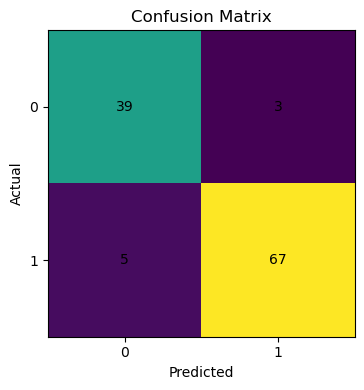

Accuracy : 0.9298245614035088
Precision: 0.9571428571428572
Recall   : 0.9305555555555556
F1 Score : 0.943661971830986


In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForest(
    n_estimators=10,
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

results = model.evaluate(y_test, y_pred)

print("Accuracy :", results["accuracy"])
print("Precision:", results["precision"])
print("Recall   :", results["recall"])
print("F1 Score :", results["f1_score"])